In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [2]:
# Generate a reproducible sample of customer behavior
X, _ = make_blobs(
    n_samples=120,
    centers=3,
    cluster_std=1.1,
    random_state=42
)

customers = pd.DataFrame(
    X,
    columns=["Annual_Spend", "Visit_Frequency"]
)

customers["Customer_ID"] = range(1001, 1001 + len(customers))
customers = customers[["Customer_ID", "Annual_Spend", "Visit_Frequency"]]

print(customers.head())
print("\nNumber of customers:", len(customers))


   Customer_ID  Annual_Spend  Visit_Frequency
0         1001     -3.036289         8.810061
1         1002     -2.524045         7.850804
2         1003     -3.623312         9.359958
3         1004     -1.615419        10.506150
4         1005     -7.226423        -6.045243

Number of customers: 120


In [3]:
print(customers.info())
print("\nSummary statistics:")
print(customers[["Annual_Spend", "Visit_Frequency"]].describe())
print("\nMissing values:")
print(customers.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      120 non-null    int64  
 1   Annual_Spend     120 non-null    float64
 2   Visit_Frequency  120 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.9 KB
None

Summary statistics:
       Annual_Spend  Visit_Frequency
count    120.000000       120.000000
mean      -1.695362         1.447498
std        4.870810         6.466373
min       -9.107284        -8.934101
25%       -6.315852        -5.949377
50%       -2.612410         2.202458
75%        3.665959         8.243007
max        6.714683        11.051792

Missing values:
Customer_ID        0
Annual_Spend       0
Visit_Frequency    0
dtype: int64


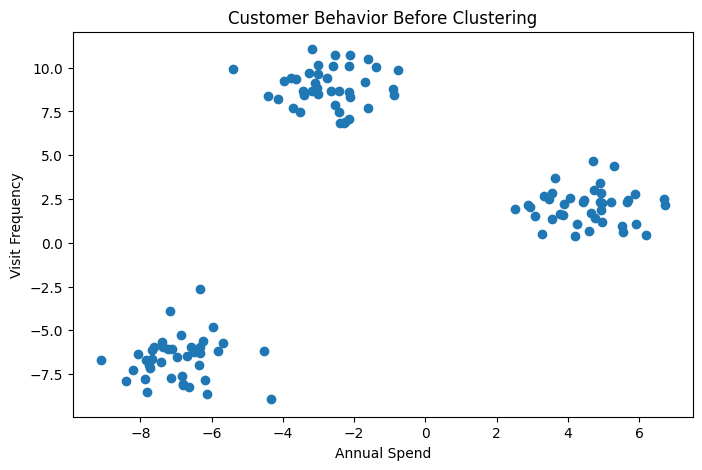

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(customers["Annual_Spend"], customers["Visit_Frequency"])
plt.xlabel("Annual Spend")
plt.ylabel("Visit Frequency")
plt.title("Customer Behavior Before Clustering")
plt.show()


In [5]:
features = customers[["Annual_Spend", "Visit_Frequency"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("First five standardized rows:")
print(X_scaled[:5])


First five standardized rows:
[[-0.2764529   1.14336627]
 [-0.17084573  0.99439881]
 [-0.39747668  1.22876229]
 [ 0.01648144  1.40675972]
 [-1.14031382 -1.16358236]]


In [6]:
silhouette_scores = {}

for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

for k, score in silhouette_scores.items():
    print(f"Clusters = {k}: silhouette score = {score:.3f}")


Clusters = 2: silhouette score = 0.678
Clusters = 3: silhouette score = 0.832
Clusters = 4: silhouette score = 0.680
Clusters = 5: silhouette score = 0.507
Clusters = 6: silhouette score = 0.352


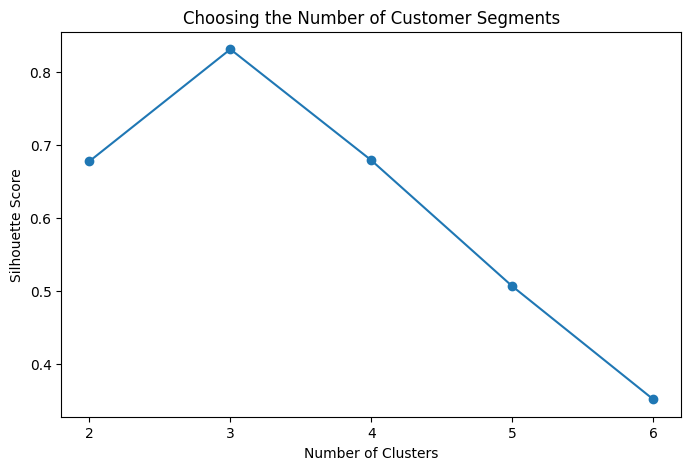

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker="o"
)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Choosing the Number of Customer Segments")
plt.xticks(range(2, 7))
plt.show()


In [8]:
final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customers["Segment"] = final_model.fit_predict(X_scaled)

print(customers.head(10))


   Customer_ID  Annual_Spend  Visit_Frequency  Segment
0         1001     -3.036289         8.810061        2
1         1002     -2.524045         7.850804        2
2         1003     -3.623312         9.359958        2
3         1004     -1.615419        10.506150        2
4         1005     -7.226423        -6.045243        1
5         1006     -4.135572         8.222457        2
6         1007     -6.486061        -6.263247        1
7         1008     -1.604398         7.671358        2
8         1009     -2.144808        10.087386        2
9         1010     -6.644124        -8.250422        1


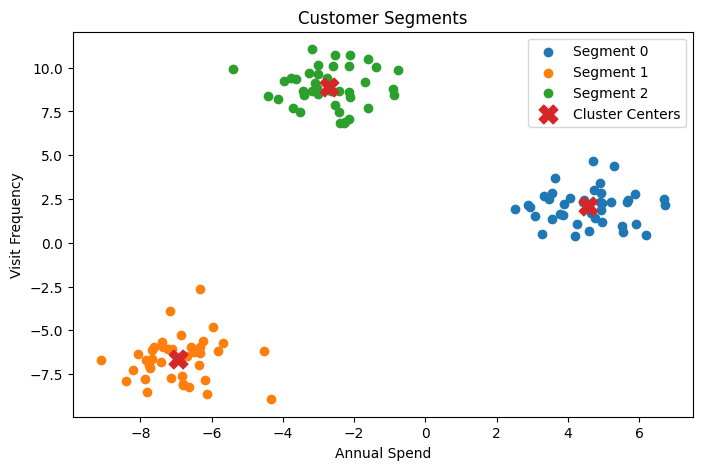

In [9]:
plt.figure(figsize=(8, 5))

for segment in sorted(customers["Segment"].unique()):
    group = customers[customers["Segment"] == segment]
    plt.scatter(
        group["Annual_Spend"],
        group["Visit_Frequency"],
        label=f"Segment {segment}"
    )

# Convert standardized centroids back to the original scale
centers = scaler.inverse_transform(final_model.cluster_centers_)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=180,
    label="Cluster Centers"
)

plt.xlabel("Annual Spend")
plt.ylabel("Visit Frequency")
plt.title("Customer Segments")
plt.legend()
plt.show()


In [10]:
segment_profile = (
    customers
    .groupby("Segment")[["Annual_Spend", "Visit_Frequency"]]
    .mean()
    .round(2)
)

segment_profile["Customer_Count"] = customers["Segment"].value_counts().sort_index()

print(segment_profile)


         Annual_Spend  Visit_Frequency  Customer_Count
Segment                                               
0                4.56             2.07              40
1               -6.94            -6.61              40
2               -2.71             8.88              40


In [11]:
new_customer = pd.DataFrame({
    "Annual_Spend": [2.0],
    "Visit_Frequency": [2.2]
})

new_customer_scaled = scaler.transform(new_customer)
predicted_segment = final_model.predict(new_customer_scaled)[0]

print("New customer:")
print(new_customer)
print("\nPredicted segment:", predicted_segment)


New customer:
   Annual_Spend  Visit_Frequency
0           2.0              2.2

Predicted segment: 0
